# 01 - Exploratory Data Analysis: PneumoniaMNIST

Goal: understand the dataset before training any model (size, class imbalance, image appearance and pixel statistics).

In [1]:
import sys
sys.path.append("..")  # allows importing from src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import get_dataset, get_spec
from src.utils import set_seed

set_seed(42)
FLAG = "pneumoniamnist"
SIZE = 28  # 28, 64, 128 or 224 (MedMNIST+)


## 1. Dataset specification

In [2]:
spec = get_spec(FLAG)
print(spec)

DatasetSpec(flag='pneumoniamnist', task='binary-class', n_channels=1, n_classes=2, labels={'0': 'normal', '1': 'pneumonia'})


## 2. Loading the splits

The download happens on the first run.

In [3]:
splits = {s: get_dataset(FLAG, s, size=SIZE, root="../data") for s in ["train", "val", "test"]}
for name, ds in splits.items():
    print(f"{name:>5}: {len(ds):>5} images | image array shape: {ds.imgs.shape}")

train:  4708 images | image array shape: (4708, 28, 28)
  val:   524 images | image array shape: (524, 28, 28)
 test:   624 images | image array shape: (624, 28, 28)


## 3. Class distribution

Class imbalance matters: it affects the choice of metrics (accuracy alone can be misleading) and possibly the loss function.

,split,class,n,proportion
0,train,normal,1214,0.257859
1,train,pneumonia,3494,0.742141
2,val,normal,135,0.257634
3,val,pneumonia,389,0.742366
4,test,normal,234,0.375000
5,test,pneumonia,390,0.625000


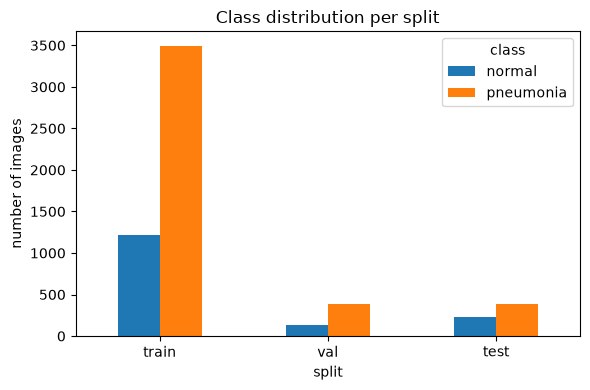

In [4]:
rows = []
for name, ds in splits.items():
    labels = ds.labels.flatten()
    for cls, count in zip(*np.unique(labels, return_counts=True)):
        rows.append({"split": name, "class": spec.labels[str(cls)], "n": count})
df = pd.DataFrame(rows)
df["proportion"] = df.groupby("split")["n"].transform(lambda x: x / x.sum())
display(df)

pivot = df.pivot(index="split", columns="class", values="n").loc[["train", "val", "test"]]
pivot.plot(kind="bar", figsize=(6, 4), rot=0)
plt.ylabel("number of images"); plt.title("Class distribution per split")
plt.tight_layout(); plt.show()

## 4. Visual examples

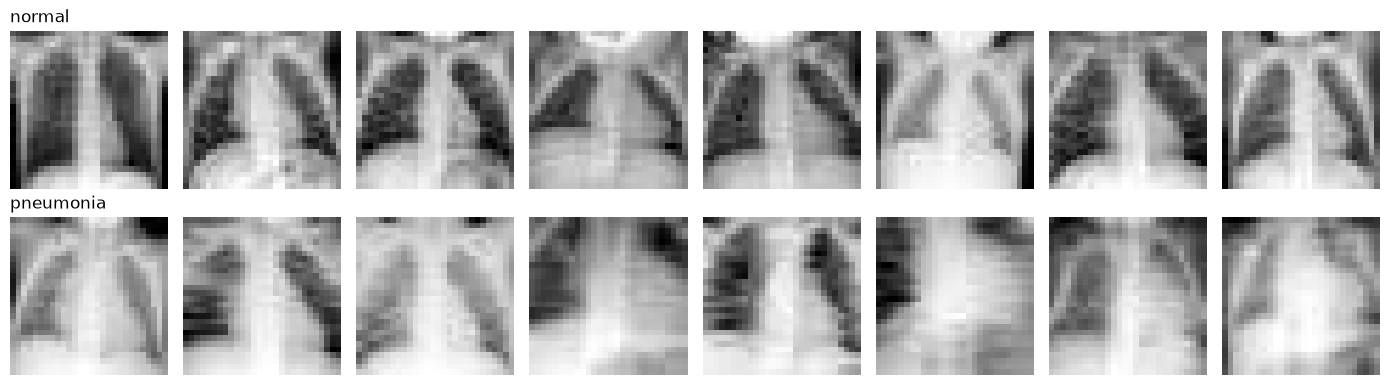

In [5]:
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
train = splits["train"]
for row, cls in enumerate([0, 1]):
    idx = np.where(train.labels.flatten() == cls)[0][:8]
    for ax, i in zip(axes[row], idx):
        ax.imshow(train.imgs[i], cmap="gray"); ax.axis("off")
    axes[row][0].set_title(spec.labels[str(cls)], loc="left")
plt.tight_layout(); plt.show()

## 5. Pixel statistics

Used to decide on normalization (for now we use mean 0.5 / std 0.5).

global mean: 0.5719 | std: 0.1684
min: 0.00 | max: 1.00


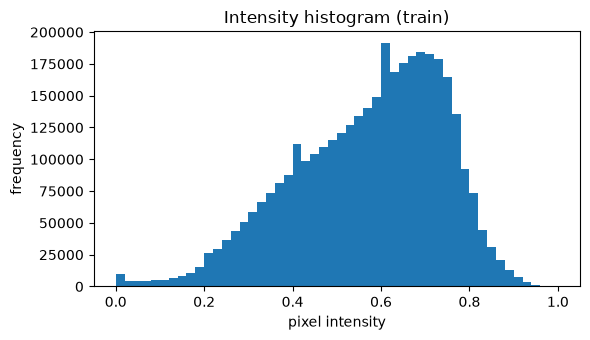

In [6]:
imgs = train.imgs.astype(np.float32) / 255.0
print(f"global mean: {imgs.mean():.4f} | std: {imgs.std():.4f}")
print(f"min: {imgs.min():.2f} | max: {imgs.max():.2f}")

plt.figure(figsize=(6, 3.5))
plt.hist(imgs.flatten(), bins=50)
plt.xlabel("pixel intensity"); plt.ylabel("frequency")
plt.title("Intensity histogram (train)")
plt.tight_layout(); plt.show()

## 6. Observations


**Class distribution.** The training set contains 4,708 images (74.2% pneumonia, 25.8% normal) and the validation set has 524 images with virtually the same proportions. The test set has 624 images and a noticeably different balance: 62.5% pneumonia and 37.5% normal. The splits are the official ones provided by MedMNIST, so this shift between train/val and test is a property of the benchmark, not a choice of mine.

**Implications for evaluation.** The dataset is imbalanced, so accuracy alone is misleading: always predicting "pneumonia" would already score 74.2% on train/val and 62.5% on test. I will report AUC, sensitivity, specificity, balanced accuracy and the confusion matrix, and compare every model against this majority-class baseline. Because the validation set mirrors the training distribution but not the test set, validation metrics may be optimistic for the test set; AUC is less sensitive to this shift than accuracy. A model that leans toward the majority class may lose specificity on the test set, so I will watch for that. A class-weighted loss is a candidate experiment for later.

**Visual inspection.** **Visual inspection.** At 28×28 the differences are subtle. Pneumonia images tend to look hazier, with less contrast between the lung fields and the central region, while normal images often show darker, better-defined lung fields. There is considerable overlap, though, and exposure and positioning vary between images. Mean pixel intensity in the training set is slightly higher for pneumonia (0.5800) than for normal (0.5486), but the gap is small (about 0.03 on a [0, 1] scale), so brightness alone is unlikely to separate the classes. Later, I will check whether the models rely on global brightness instead of local patterns, for example by comparing them with a brightness-only baseline.

**Pixel statistics.** Pixel intensities in the training set (scaled to [0, 1]) have a mean of 0.5719 and a standard deviation of 0.1684. The histogram is left-skewed: most values fall between 0.2 and 0.85, with a main peak around 0.6-0.75, a secondary bump near 0.4, and a small spike at 0.0 (likely black borders or background). Almost no pixels are close to 1.0, so the images use a fairly narrow intensity range.

**Normalization decision.** I will normalize with the training-set statistics (mean = 0.5719, std = 0.1684), computed on the training split only to avoid data leakage, and use the same values for every model so the comparison stays fair. This gives approximately zero-mean, unit-variance inputs, whereas the benchmark default (0.5 / 0.5) would leave a standard deviation of about 0.34.